# Valorant

Датасет [Roboflow Valorant v3](https://universe.roboflow.com/daniels-magonis-0pjzx/valorant-9ufcp/dataset/3), лицензия CC BY 4.0.

In [13]:
%pip install numpy pandas pillow scipy matplotlib pyyaml

Note: you may need to restart the kernel to use updated packages.


d:\MAI\ADKursa4\.venv\Scripts\python.exe: No module named pip


In [ ]:
from collections import defaultdict
from hashlib import sha256
from io import BytesIO
from itertools import combinations
from pathlib import Path
from tempfile import TemporaryDirectory
from zipfile import ZIP_DEFLATED, ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image
from scipy.fft import dctn
from scipy.optimize import linear_sum_assignment

SOURCE = Path("valorant_data")
OUTPUT = Path("valorant_clean_yolo.zip")
SPLITS = ("train", "valid", "test")
PRIORITY = ("test", "valid", "train")
PHASH_MAX = 4
IOU_MIN = 0.5
SEED = 42


## 1. Чтение кадров и разметки

Считаем SHA-256 для точных копий и 64-битный pHash для визуально похожих изображений. Для сопоставления рамок используем нормированные координаты YOLO. Для EDA переводим ширину, высоту и площадь рамок в пиксели.

In [ ]:
def perceptual_hash(image):
    gray = image.convert("L").resize((32, 32), Image.Resampling.LANCZOS)
    low_freq = dctn(np.asarray(gray, dtype=float))[:8, :8]
    bits = np.packbits(low_freq > np.median(low_freq))
    return int.from_bytes(bits.tobytes(), "big")


rows = []
names = yaml.safe_load((SOURCE / "data.yaml").read_text(encoding="utf-8-sig"))["names"]
classes = ({int(k): v for k, v in names.items()}
           if isinstance(names, dict) else dict(enumerate(names)))

for split in SPLITS:
    images = sorted(
        p.relative_to(SOURCE).as_posix()
        for p in (SOURCE / split / "images").rglob("*")
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )
    for file in images:
        label = f"{split}/labels/{Path(file).with_suffix('.txt').name}"
        label_path = SOURCE / label
        has_label = label_path.is_file()
        content = (SOURCE / file).read_bytes()
        with Image.open(BytesIO(content)) as image:
            width, height = image.size
            phash = perceptual_hash(image)

        boxes = []
        if has_label:
            for line in label_path.read_text(encoding="utf-8-sig").splitlines():
                if not line.strip():
                    continue
                cls, x, y, w, h = line.split()
                cls = int(cls)
                x, y, w, h = map(float, (x, y, w, h))
                if cls not in classes or not all(np.isfinite([x, y, w, h])) or min(w, h) <= 0:
                    raise ValueError(f"Некорректная разметка {label}: {line}")
                boxes.append((cls, x - w / 2, y - h / 2, x + w / 2, y + h / 2))

        rows.append({
            "split": split, "file": file, "label": label, "has_label": has_label,
            "width": width, "height": height, "boxes": tuple(sorted(boxes)),
            "n_objects": len(boxes), "sha256": sha256(content).hexdigest(), "phash": phash,
        })

frames = pd.DataFrame(rows)
if frames.empty:
    raise ValueError("В valorant_data нет изображений в train/images, valid/images или test/images.")
items = list(frames.itertuples(index=False))
print(f"Кадров: {len(items):,} · рамок: {frames.n_objects.sum():,}".replace(",", " "))
print(f"Пустых кадров: {(frames.n_objects == 0).sum()} · без файла разметки: {(~frames.has_label).sum()}")
display(frames.groupby(["width", "height"]).size().rename("Кадров").to_frame()
        .rename_axis(["Ширина, px", "Высота, px"]))

## 2. Точные и почти одинаковые кадры

- **Точная копия** — тот же SHA-256. Если разметка копий расходится, выбираем один файл по приоритету частей и выводим число конфликтов.
- **Почти-копия** — pHash отличается максимум на 4 бита, количество рамок каждого класса совпадает и каждой рамке можно сопоставить отдельную рамку того же класса с IoU ≥ 0,5. IoU — площадь пересечения рамок, делённая на площадь их объединения.

Оба правила действуют внутри частей и между ними. Сначала выбираем по одной точной копии, затем сравниваем оставшиеся кадры. Сохраняем исходную часть выбранного кадра. Приоритет `test → valid → train` сохраняет больше кадров для оценки. Внутри каждой части порядок фиксирует `SEED`.

In [3]:
def iou(a, b):
    _, ax1, ay1, ax2, ay2 = a
    _, bx1, by1, bx2, by2 = b
    overlap = (max(0, min(ax2, bx2) - max(ax1, bx1))
               * max(0, min(ay2, by2) - max(ay1, by1)))
    union = (ax2 - ax1) * (ay2 - ay1) + (bx2 - bx1) * (by2 - by1) - overlap
    return overlap / union


def boxes_match(left, right):
    if not left:
        return True
    if len(left) == 1:
        return iou(left[0], right[0]) >= IOU_MIN
    allowed = np.array([
        [a[0] == b[0] and iou(a, b) >= IOU_MIN for b in right]
        for a in left
    ])
    row, col = linear_sum_assignment(~allowed)
    return allowed[row, col].all()


exact_groups = defaultdict(list)
by_classes = defaultdict(list)
near = [set() for _ in items]

# Ищем похожие пары среди кадров с одинаковым составом классов.
for i, item in enumerate(items):
    exact_groups[item.sha256].append(i)
    signature = tuple(box[0] for box in item.boxes)
    for j in by_classes[signature]:
        other = items[j]
        if ((item.phash ^ other.phash).bit_count() <= PHASH_MAX
            and item.sha256 != other.sha256
            and boxes_match(item.boxes, other.boxes)):
            near[i].add(j)
            near[j].add(i)
    by_classes[signature].append(i)

priority = {split: rank for rank, split in enumerate(PRIORITY)}
order = sorted(np.random.default_rng(SEED).permutation(len(items)),
               key=lambda i: priority[items[i].split])
first_exact = {}
reason = {}
matched = {}
kept = set()

for i in order:
    digest = items[i].sha256
    if digest in first_exact:
        reason[i], matched[i] = "exact", first_exact[digest]
        continue
    first_exact[digest] = i

    candidates = near[i] & kept
    if candidates:
        j = min(candidates, key=lambda j: ((items[i].phash ^ items[j].phash).bit_count(), j))
        reason[i], matched[i] = "near", j
    else:
        reason[i] = "kept"
        kept.add(i)

audit = frames[["split", "file"]].copy()
audit["keep"] = audit.index.isin(kept).astype(int)
audit["reason"] = audit.index.map(reason)
audit["matched_file"] = [items[matched[i]].file if i in matched else "" for i in audit.index]
audit["kept_file"] = [
    items[matched.get(matched.get(i, i), matched.get(i, i))].file for i in audit.index
]

assert sum(audit.keep) == len({items[i].sha256 for i in kept})
assert all(not (near[i] & kept) for i in kept)

conflicts = sum(len({items[i].boxes for i in group}) > 1 for group in exact_groups.values())
print(f"Групп точных копий с разной разметкой: {conflicts}")
display(audit.reason.value_counts().reindex(["kept", "exact", "near"], fill_value=0)
        .rename(index={"kept": "Оставлено", "exact": "Удалено точных копий",
                       "near": "Удалено почти-копий"}).rename("Кадров").to_frame())

Групп точных копий с разной разметкой: 0


,Кадров
reason,
Оставлено,5124
Удалено точных копий,693
Удалено почти-копий,4081


## 3. EDA до и после очистки

Распределение кадров по частям, количество рамок каждого класса и их размеры. В таблице по классам один кадр может дать несколько рамок.

,До,После,Удалено
Часть,,,
train,6927,3008,3919
valid,1983,1261,722
test,988,855,133
Всего,9898,5124,4774


До            После           
split         train valid test train valid test
Класс                                          
dropped spike   396   117   62   283    94   60
enemy          3729  1047  520  1607   706  456
planted spike   461   162   72   289   134   67
teammate       2598   746  371  1010   404  308

,"Ширина, px","Высота, px","Площадь, px²"
Класс,,,
dropped spike,18.5,25.0,471.7
enemy,9.5,33.5,312.8
planted spike,12.5,37.5,437.5
teammate,12.5,41.5,494.5


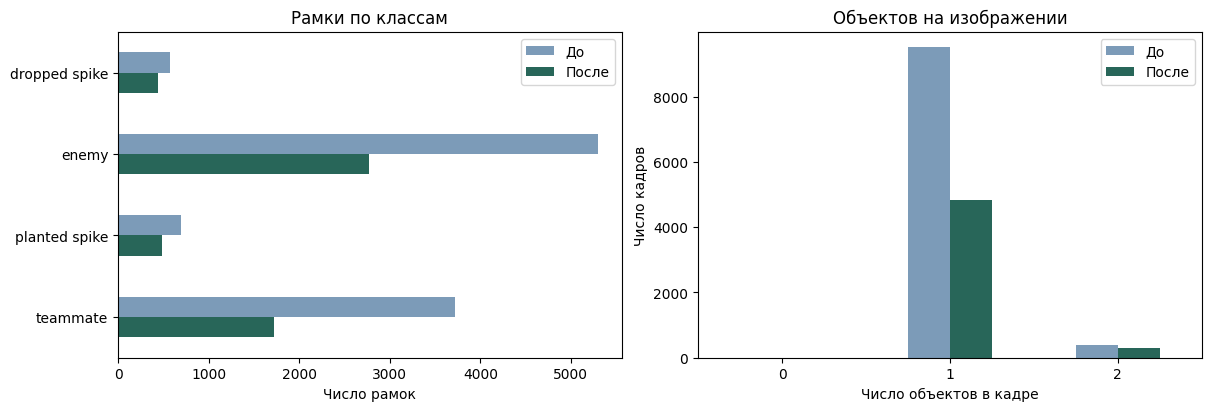

In [4]:
split_summary = pd.DataFrame({
    "До": frames.groupby("split").size(),
    "После": frames.loc[sorted(kept)].groupby("split").size(),
}).reindex(SPLITS).fillna(0).astype(int)
split_summary.loc["Всего"] = split_summary.sum()
split_summary["Удалено"] = split_summary["До"] - split_summary["После"]
display(split_summary.rename_axis("Часть"))

objects = pd.DataFrame([
    (i in kept, item.split, classes[c], (x2 - x1) * item.width, (y2 - y1) * item.height)
    for i, item in enumerate(items) for c, x1, y1, x2, y2 in item.boxes
], columns=["keep", "split", "class", "width_px", "height_px"])
objects["area_px"] = objects.width_px * objects.height_px

class_summary = pd.concat([
    pd.crosstab(objects["class"], objects.split).reindex(columns=SPLITS, fill_value=0),
    pd.crosstab(objects.loc[objects.keep, "class"], objects.loc[objects.keep, "split"])
    .reindex(columns=SPLITS, fill_value=0),
], axis=1, keys=["До", "После"]).reindex(classes.values()).fillna(0).astype(int)
display(class_summary.rename_axis("Класс"))

display(objects.groupby("class")[["width_px", "height_px", "area_px"]].median()
        .round(1).rename(columns={"width_px": "Ширина, px", "height_px": "Высота, px",
                                  "area_px": "Площадь, px²"}).rename_axis("Класс"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
class_counts = pd.DataFrame({stage: class_summary[stage].sum(axis=1) for stage in ["До", "После"]})
class_counts.plot.barh(ax=axes[0], color=["#7c9bb8", "#286659"], rot=0)
axes[0].set(xlabel="Число рамок", ylabel="", title="Рамки по классам", ylim=(len(classes) - 0.5, -0.5))

objects_per_frame = pd.crosstab(frames.n_objects, audit.keep).reindex(columns=[0, 1], fill_value=0)
pd.DataFrame({"До": objects_per_frame.sum(axis=1), "После": objects_per_frame[1]}).plot.bar(
    ax=axes[1], color=["#7c9bb8", "#286659"], rot=0
)
axes[1].set(xlabel="Число объектов в кадре", ylabel="Число кадров", title="Объектов на изображении")
display(fig)
plt.close(fig)

### Дубликаты между частями

В каждой строке считаем кадры указанной части, у которых есть хотя бы одна копия в сравниваемой части. Столбец «Любые» включает точные и почти одинаковые кадры.

In [5]:
def cross_split_matches(indices):
    indices = set(indices)
    results = []
    for split, reference in combinations(PRIORITY, 2):
        query = [i for i in indices if items[i].split == split]
        ref = {i for i in indices if items[i].split == reference}
        hashes = {items[i].sha256 for i in ref}
        exact = {i for i in query if items[i].sha256 in hashes}
        any_match = exact | {i for i in query if near[i] & ref}
        results.append({
            "Сравнение": f"{split} → {reference}", "Кадров": len(query),
            "Точные": len(exact), "Любые": len(any_match),
            "Доля любых, %": round(100 * len(any_match) / len(query), 1) if query else 0,
        })
    return pd.DataFrame(results).set_index("Сравнение")


display(pd.concat({"До": cross_split_matches(range(len(items))),
                   "После": cross_split_matches(kept)}, axis=1))

# Префикс имени объединяет серию кадров экспорта Roboflow.
series = frames.file.str.extract(r"/images/(.+?)\d+_(?:jpg|jpeg|png)\.rf\.", expand=False)
for stage, indices in [("До", frames.index), ("После", sorted(kept))]:
    series_splits = frames.loc[indices, "split"].groupby(series).nunique()
    print(f"{stage}: {len(series_splits)} серий, из них {(series_splits > 1).sum()} в нескольких частях.")

До: 34 серий, из них 34 в нескольких частях.
После: 34 серий, из них 34 в нескольких частях.


До               ...  После                    
              Кадров Точные Любые  ... Точные Любые Доля любых, %
Сравнение                          ...                           
test → valid     988     32   388  ...      0     0           0.0
test → train     988     88   614  ...      0     0           0.0
valid → train   1983    180  1277  ...      0     0           0.0

[3 rows x 8 columns]

### Примеры удалённых почти-копий

Слева — кадр, исключённый из выборки. Справа — сохранённый кадр, с которым он совпал по правилу pHash и IoU. Рамки взяты из исходной разметки.

In [ ]:
examples = [(i, j) for i, j in matched.items() if reason[i] == "near"]
examples.sort(key=lambda pair: items[pair[0]].split == items[pair[1]].split)

if examples:
    sample = examples[:2]
    fig, axes = plt.subplots(len(sample), 2, figsize=(7.2, 3.55 * len(sample)),
                             squeeze=False, layout="constrained")
    for (i, j), (left, right) in zip(sample, axes):
        distance = (items[i].phash ^ items[j].phash).bit_count()
        for k, ax, action in [(i, left, "Удалён"), (j, right, "Оставлен")]:
            item = items[k]
            with Image.open(SOURCE / item.file) as image:
                ax.imshow(image.convert("RGB"))
            for _, x1, y1, x2, y2 in item.boxes:
                ax.add_patch(Rectangle((x1 * item.width, y1 * item.height),
                                       (x2 - x1) * item.width, (y2 - y1) * item.height,
                                       fill=False, edgecolor="#66ff87", linewidth=1.5))
            ax.set_title(f"{action} ({item.split}), ΔpHash = {distance}", fontsize=10)
            ax.axis("off")
    display(fig)
    plt.close(fig)
else:
    print("Почти-копий по выбранным порогам нет.")

## 4. Экспорт очищенного датасета

Архив сохраняет структуру `train / valid / test`. В `dedup_keep.csv` есть решение для каждого исходного кадра. `matched_file` показывает прямое совпадение, `kept_file` — кадр, который вошёл в итоговый архив. Для обучения распакуйте очищенный архив и укажите путь к его `data.yaml`.

Поиск утечки здесь ограничен выбранными правилами сравнения кадров. Таблица серий показывает, что кадры из одной серии могут по-прежнему встречаться в нескольких частях.

In [ ]:
if SOURCE.resolve() == OUTPUT.resolve():
    raise ValueError("Укажите разные пути для исходной папки и очищенного архива.")

config = {
    "train": "train/images", "val": "valid/images", "test": "test/images",
    "nc": len(classes), "names": classes,
}
readme = (
    "Valorant Object Detection — очищенный датасет\n"
    "Источник: https://universe.roboflow.com/daniels-magonis-0pjzx/valorant-9ufcp/dataset/3\n"
    "Лицензия: CC BY 4.0\n"
    f"Изменения: удалены точные и почти одинаковые кадры, осталось {len(kept)} из {len(items)}.\n"
    f"Пороги: pHash ≤ {PHASH_MAX}, IoU ≥ {IOU_MIN}. Приоритет: {', '.join(PRIORITY)}. Seed: {SEED}.\n"
    "Журнал удалений: dedup_keep.csv.\n"
)

with TemporaryDirectory(dir=OUTPUT.parent) as temp:
    temp_zip = Path(temp) / OUTPUT.name
    with ZipFile(temp_zip, "w", ZIP_DEFLATED) as clean:
        for split in SPLITS:
            clean.writestr(f"{split}/images/", b"")
            clean.writestr(f"{split}/labels/", b"")
        for i in sorted(kept):
            item = items[i]
            clean.write(SOURCE / item.file, item.file)
            labels = (SOURCE / item.label).read_bytes() if item.has_label else b""
            clean.writestr(item.label, labels)

        clean.writestr("data.yaml", yaml.safe_dump(config, sort_keys=False, allow_unicode=True))
        clean.writestr("dedup_keep.csv", audit.to_csv(index=False))
        clean.writestr("README.txt", readme)
    temp_zip.replace(OUTPUT)

print(f"{OUTPUT.name} · {len(kept)} кадров · {OUTPUT.stat().st_size / 1024 ** 2:.1f} МиБ")
display(audit.loc[audit.keep == 0, ["split", "file", "reason", "kept_file"]].head(3))